# Camada Gold

### Nessa camda fizemos uma analise de resultados a apartir do tratamento de dados realizado na camada silver

##### 1. Importando bibliotecas

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

##### 2. Carregando base do arquivo parquet

In [31]:
# Carrega os dados do parquet criadp e salva em um DataFrame com nome específico para a camada Gold
df_gold = pd.read_parquet("df_carteira_cliente_silver.parquet").copy()

##### 3. Gerando graficos

##### 3.1 Grafico de que cancelou e não cancelou 

Nesse grafico fizemos um grafico de rosca que mostra o tamanho da nossa base completa e quantos clientes saíram e quantos ficaram . A maior parte continua com a gente, mas os que cancelaram são uma fatia grande da base  o suficiente para merecer atenção de como podemos melhorar.

Nessa mesma etapa optamos por olhar como funciona os contratos de que cancelou e começamos pelo tipo de contato e aqui olhamos só para quem saiu. A maioria dos cancelamentos vem do plano mensal, e os planos anual e de 2 anos de contrato aparecem com uma fatia bem menor. Isso mostra que o contrato mais longo ajuda a segurar o cliente e quem opta por contrato mais curto geralmente costuma cancelar antes de um ano.

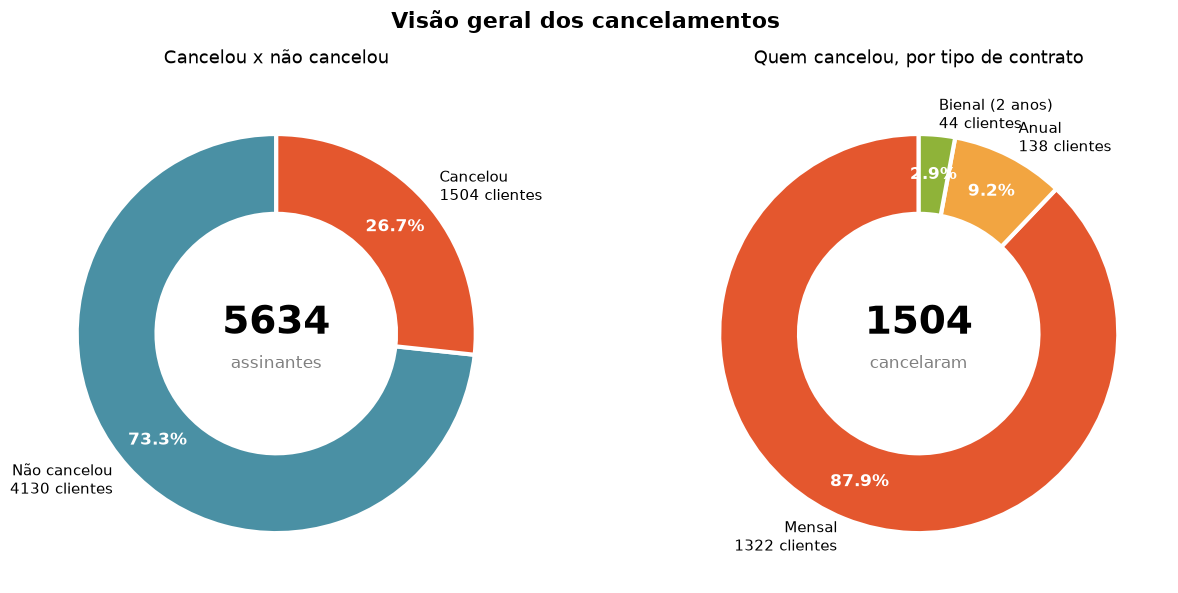

In [33]:
df["cancelou"] = (df["cancelou_contrato"] == "yes").astype(int)

total = len(df)
cancelados = df[df["cancelou"] == 1]
n_canc = len(cancelados)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle("Visão geral dos cancelamentos", fontsize=16, fontweight="bold")

rosca = {"width": 0.4, "edgecolor": "white", "linewidth": 3}

# ---------- Gráfico 1: total de assinantes ----------
qtd = df["cancelou"].value_counts().sort_index()   # 0 = não cancelou, 1 = cancelou
_, _, pct1 = ax1.pie(
    qtd,
    labels=[f"Não cancelou\n{qtd[0]} clientes", f"Cancelou\n{qtd[1]} clientes"],
    colors=["#4a90a4", "#e4572e"],
    autopct="%.1f%%",
    pctdistance=0.8,
    startangle=90,
    wedgeprops=rosca,
    textprops={"fontsize": 11},
)
ax1.text(0, 0.05, f"{total}", ha="center", va="center", fontsize=28, fontweight="bold")
ax1.text(0, -0.15, "assinantes", ha="center", va="center", fontsize=12, color="gray")

# ---------- Gráfico 2: quem cancelou, por tipo de contrato ----------
por_contrato = cancelados["tipo_de_contrato"].value_counts()
por_contrato = por_contrato.reindex(["month-to-month", "one year", "two year"]).fillna(0).astype(int)

_, _, pct2 = ax2.pie(
    por_contrato,
    labels=[f"Mensal\n{por_contrato.iloc[0]} clientes",
            f"Anual\n{por_contrato.iloc[1]} clientes",
            f"Bienal (2 anos)\n{por_contrato.iloc[2]} clientes"],
    colors=["#e4572e", "#f2a541", "#8fb339"],
    autopct="%.1f%%",
    pctdistance=0.8,
    startangle=90,
    wedgeprops=rosca,
    textprops={"fontsize": 11},
)
ax2.text(0, 0.05, f"{n_canc}", ha="center", va="center", fontsize=28, fontweight="bold")
ax2.text(0, -0.15, "cancelaram", ha="center", va="center", fontsize=12, color="gray")

ax1.set_title("Cancelou x não cancelou", fontsize=13, pad=15)
ax2.set_title("Quem cancelou, por tipo de contrato", fontsize=13, pad=15)

# porcentagem em branco e negrito dentro da rosca
for t in pct1 + pct2:
    t.set_color("white")
    t.set_fontweight("bold")
    t.set_fontsize(12)

plt.tight_layout()
plt.show()

##### 3.2 Cancelamento por tempo de contrato
A partir do grafico do tipo de contrato decidimos explorar a frequencia por faixa etaria de tempo que os clientes costumam cancelar para identifacar um foco de cancelamento e descobrir o periodo destes cancelamento sendo assim  esse gráfico mostra que o cliente novo é o que mais cancela. Nos primeiros meses a taxa é bem alta e vai caindo conforme o cliente fica mais tempo conosco. Por isso o começo do relacionamento é a fase mais importante para segurar o cliente.

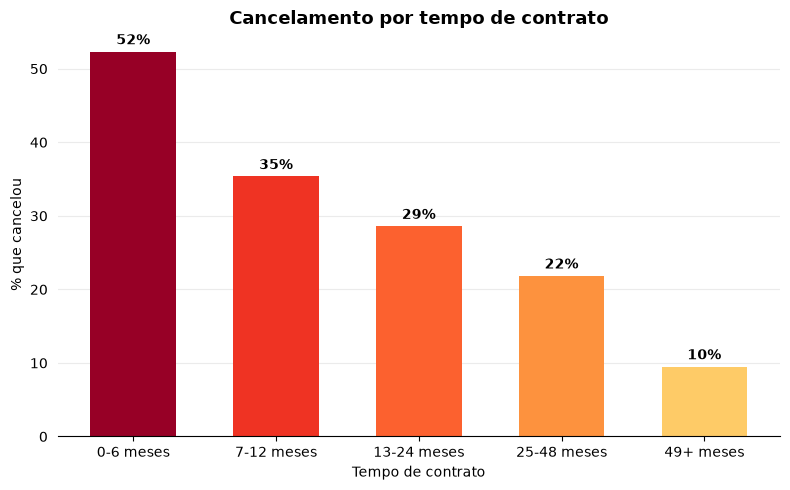

In [36]:
df["faixa_tempo"] = pd.cut(
    df["tempo_de_contrato"],
    bins=[-1, 6, 12, 24, 48, 100],
    labels=["0-6 meses", "7-12 meses", "13-24 meses", "25-48 meses", "49+ meses"],
)
taxa = df.groupby("faixa_tempo", observed=True)["cancelou"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(taxa.index.astype(str), taxa * 100, color=cor_da_taxa(taxa), width=0.6)

for i, v in enumerate(taxa):
    ax.text(i, v * 100 + 1, f"{v:.0%}", ha="center", fontweight="bold")

ax.set_title("Cancelamento por tempo de contrato", fontsize=13, fontweight="bold")
ax.set_xlabel("Tempo de contrato")
ax.set_ylabel("% que cancelou")
estilo(ax)
plt.tight_layout()
plt.show()


##### 3.2 O que os clientes dizem no feedback
 Neste grafico decidimos explorar os feedbacks com foco nos clientes que cancelaram para para saber o que os clientes dizem sobre os nossos produtos e expicar o pico de cancelamento que ocorre nos primeiros meses de assinatura e comparar com os clientes que ainda continuam assinates para saber o que que continua acha positivo que cancela descorda e apartir disto o grafico mostra que os clientes que cancelaram falam mais de preço alto, de lentidão e instabilidade, de cheque eletrônico e de contrato mensal do que os que ficaram. Assim isso ajuda a entender o motivo da saída, e não só quem saiu.

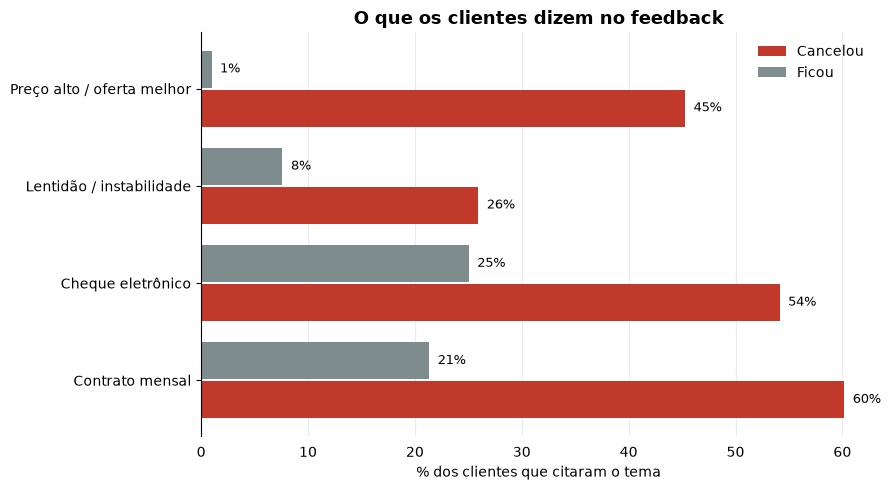

In [35]:
temas = {
    "Preço alto / oferta melhor": r"\bhigh\b|expensive|overpriced|pricey|better deal|cheaper|competitive|better value",
    "Lentidão / instabilidade": r"slow|unreliable|outage|interruption|inconsistent|frequent",
    "Cheque eletrônico": r"electronic check",
    "Contrato mensal": r"month-to-month",
}

texto = df["feedback_cliente"].str.lower()

nomes, cancelou, ficou = [], [], []
for nome, padrao in temas.items():
    achou = texto.str.contains(padrao, regex=True)
    nomes.append(nome)
    cancelou.append(achou[df["cancelou"] == 1].mean() * 100)
    ficou.append(achou[df["cancelou"] == 0].mean() * 100)

pos = list(range(len(nomes)))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([p + 0.2 for p in pos], cancelou, height=0.38, color="#c0392b", label="Cancelou")
ax.barh([p - 0.2 for p in pos], ficou, height=0.38, color="#7f8c8d", label="Ficou")

# valor ao lado de cada barra
for p, v in zip(pos, cancelou):
    ax.text(v + 0.8, p + 0.2, f"{v:.0f}%", va="center", fontsize=9)
for p, v in zip(pos, ficou):
    ax.text(v + 0.8, p - 0.2, f"{v:.0f}%", va="center", fontsize=9)

ax.set_yticks(pos)
ax.set_yticklabels(nomes)
ax.invert_yaxis()  # primeiro tema fica no topo
ax.set_xlabel("% dos clientes que citaram o tema")
ax.set_title("O que os clientes dizem no feedback", fontsize=13, fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(bottom=False)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
